# Fake News Detection — Phase 4: Deep Learning with TensorFlow / Keras

**Goal:** Replace the classical classifiers from Phase 3 with a Feedforward Neural Network
built in Keras. The TF-IDF vectorisation pipeline is kept identical; only the model layer
changes. Architecture choices follow the CSE 589 lecture guidelines:
- Dense hidden layers + **ReLU** (avoids vanishing gradient)
- **Dropout** regularisation (prevents overfitting on our small 198-row dataset)
- **Sigmoid** output for binary classification
- **Adam** optimiser + **binary crossentropy** loss
- **EarlyStopping** on validation loss to avoid over-training

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

sns.set_style('whitegrid')
print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


## 1. Load Cleaned Data

In [2]:
df = pd.read_csv('fake_news_data_clean.csv')
print('Dataset shape:', df.shape)
print('Label distribution:')
print(df['label'].value_counts())
df.head(2)

Dataset shape: (198, 12)
Label distribution:
label
0    100
1     98
Name: count, dtype: int64


,title,clean_title,text,clean_text,date,year,month,text_length,word_count,title_upper_ratio,fake_or_factual,label
0,HOLLYWEIRD LIB SUSAN SARANDON Compares Muslim ...,hollyweird lib susan sarandon compares muslim ...,There are two small problems with your analogy...,two small problems analogy susan jesus muslim ...,12/30/2015,2015,12,1992,182,0.524590,Fake News,1
1,Elijah Cummings Called Trump Out To His Face A...,elijah cummings called trump face heres pathet...,Buried in Trump s bonkers interview with New Y...,buried trump bonkers interview new york times ...,4/6/2017,2017,4,2836,251,0.233766,Fake News,1


## 2. Vectorise & Split

The TF-IDF setup is identical to Phase 3. The only addition is `.toarray()`, which
converts the sparse scipy matrix to a dense NumPy array — the format Keras Dense
layers require.

In [3]:
X = df['clean_text']
y = df['label']

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

tfidf = TfidfVectorizer(max_features=5000, min_df=2)

# .toarray() converts sparse matrix → dense NumPy array (required by Keras)
X_train = tfidf.fit_transform(X_train_text).toarray()
X_test  = tfidf.transform(X_test_text).toarray()

print('Train shape:', X_train.shape)   # (n_samples, 5000)
print('Test shape: ', X_test.shape)
print('dtype:', X_train.dtype)

Train shape: (158, 3401)
Test shape:  (40, 3401)
dtype: float64


## 3. Build the Feedforward Neural Network


| Layer | Units | Activation | Notes |
|---|---|---|---|
| Input | 5000 | — | TF-IDF feature dimension |
| Dense | 256 | ReLU | Learns high-level text patterns |
| Dropout | 0.5 | — | Drops 50 % of neurons each step to prevent overfitting |
| Dense | 128 | ReLU | Intermediate abstraction |
| Dropout | 0.5 | — | |
| Dense | 64 | ReLU | Final feature compression |
| Dropout | 0.3 | — | Lighter regularisation near output |
| Dense | **1** | **Sigmoid** | Binary output probability ∈ (0, 1) |


In [5]:
INPUT_DIM = X_train.shape[1]   # 5000 (TF-IDF features)

model = Sequential([
    Input(shape=(INPUT_DIM,)),

    # Hidden layer 1 — extracts high-level patterns
    Dense(256, activation='relu'),
    Dropout(0.5),

    # Hidden layer 2 — intermediate abstraction
    Dense(128, activation='relu'),
    Dropout(0.5),

    # Hidden layer 3 — feature compression
    Dense(64, activation='relu'),
    Dropout(0.3),

    # Output — single node, Sigmoid for binary classification
    Dense(1, activation='sigmoid'),
], name='FakeNewsDetector')

model.summary()

Model: "FakeNewsDetector"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 256)            │       870,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 912,129 (3.48 MB)

 Trainable params: 912,129 (3.48 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Compile the Model

- **Adam**: Combines momentum (RMSProp) and adaptive learning rates — best default
  optimiser for most deep learning tasks
  
- **binary_crossentropy**: Correct loss for a single Sigmoid output node. Uses the
  formula $-[y \log(\hat{y}) + (1-y) \log(1-\hat{y})]$ (derived from CCE, lecture §4).
- **accuracy**: Primary metric to watch during training.

In [6]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

## 5. Train with Early Stopping

Because our dataset has only **198 rows**, overfitting is a real risk. We use:
- `validation_split=0.15` — hold out 15 % of training data to monitor generalisation.
- `EarlyStopping(patience=15)` — stops training if `val_loss` does not improve for
  15 consecutive epochs, and restores the weights from the best epoch.
- `batch_size=16` — mini-batch training; smaller batches suit our tiny dataset better
  than the default 32 (lecture §4: mini-batch gradient descent).
- `epochs=200` — a high ceiling; Early Stopping will cut this short automatically.

In [7]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    X_train, y_train,
    epochs=200,
    batch_size=16,
    validation_split=0.15,
    callbacks=[early_stop],
    verbose=1
)

print(f'\nTraining stopped at epoch {len(history.history["loss"])}')

Epoch 1/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.4254 - loss: 0.6938 - val_accuracy: 0.4167 - val_loss: 0.6940
Epoch 2/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5448 - loss: 0.6863 - val_accuracy: 0.3750 - val_loss: 0.6967
Epoch 3/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6940 - loss: 0.6671 - val_accuracy: 0.4583 - val_loss: 0.6853
Epoch 4/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8507 - loss: 0.6235 - val_accuracy: 0.6250 - val_loss: 0.6605
Epoch 5/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9328 - loss: 0.5284 - val_accuracy: 0.7083 - val_loss: 0.5894
Epoch 6/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 1.0000 - loss: 0.3488 - val_accuracy: 0.7500 - val_loss: 0.4799
Epoch 7/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 1.0000 - loss: 0.1593 - val_accuracy: 0.8750 - val_loss: 0.3210
Epoch 8/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 1.0000 - loss: 0.0526 - val_accuracy: 0.9167 - val_loss:

## 6. Training History — Loss & Accuracy Curves

A widening gap between training and validation curves indicates overfitting.
Early Stopping should have caught this before it became severe.

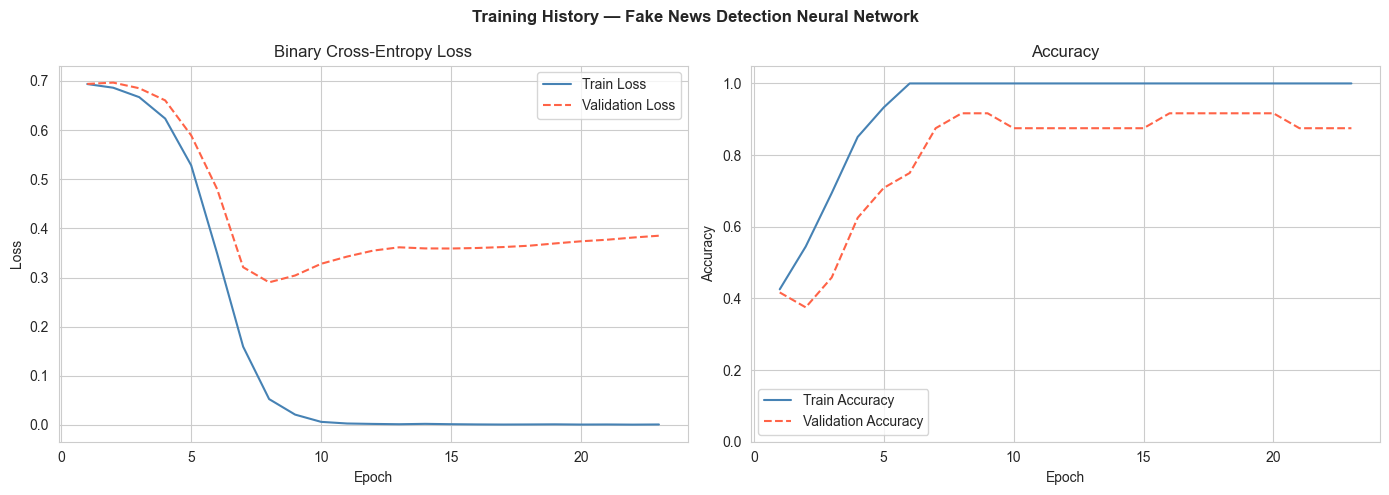

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

epochs_ran = range(1, len(history.history['loss']) + 1)

# Loss curves
ax1.plot(epochs_ran, history.history['loss'],     label='Train Loss',      color='steelblue')
ax1.plot(epochs_ran, history.history['val_loss'], label='Validation Loss',  color='tomato', linestyle='--')
ax1.set_title('Binary Cross-Entropy Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()

# Accuracy curves
ax2.plot(epochs_ran, history.history['accuracy'],     label='Train Accuracy',      color='steelblue')
ax2.plot(epochs_ran, history.history['val_accuracy'], label='Validation Accuracy',  color='tomato', linestyle='--')
ax2.set_title('Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.set_ylim(0, 1.05)
ax2.legend()

plt.suptitle('Training History — Fake News Detection Neural Network', fontweight='bold')
plt.tight_layout()
plt.show()

## 7. Evaluate on the Test Set

Predictions come out as probabilities (0–1 from Sigmoid). We threshold at 0.5 to
convert them to hard class labels (0 = Factual, 1 = Fake).

In [9]:
# Raw probabilities → hard class labels
y_prob = model.predict(X_test, verbose=0).flatten()   # shape (n,)
y_pred = (y_prob >= 0.5).astype(int)

test_acc = accuracy_score(y_test, y_pred)
print(f'Test Accuracy: {test_acc:.2%}')
print()
print(classification_report(y_test, y_pred, target_names=['Factual News', 'Fake News']))

Test Accuracy: 97.50%

              precision    recall  f1-score   support

Factual News       0.95      1.00      0.98        20
   Fake News       1.00      0.95      0.97        20

    accuracy                           0.97        40
   macro avg       0.98      0.97      0.97        40
weighted avg       0.98      0.97      0.97        40



## 8. Confusion Matrix

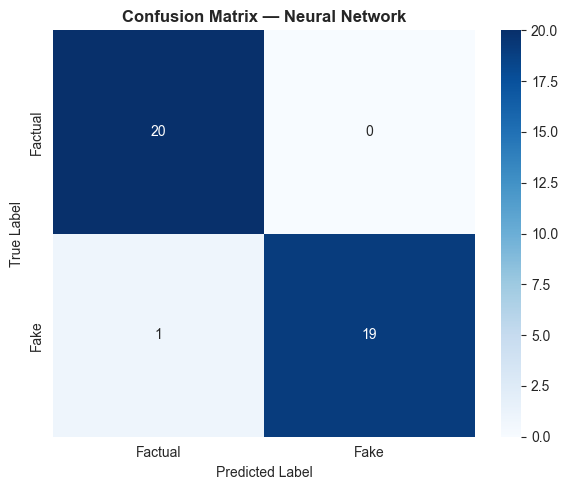

True Positives  (Fake correctly caught): 19
True Negatives  (Factual correctly passed): 20
False Positives (Factual flagged as Fake): 0
False Negatives (Fake missed as Factual): 1


In [10]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Factual', 'Fake'],
    yticklabels=['Factual', 'Fake'],
    ax=ax
)
ax.set_title('Confusion Matrix — Neural Network', fontweight='bold')
ax.set_xlabel('Predicted Label')
ax.set_ylabel('True Label')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'True Positives  (Fake correctly caught): {tp}')
print(f'True Negatives  (Factual correctly passed): {tn}')
print(f'False Positives (Factual flagged as Fake): {fp}')
print(f'False Negatives (Fake missed as Factual): {fn}')

## 9. Prediction Confidence Distribution

A well-calibrated model pushes probabilities towards 0 and 1 (confident).
A poorly calibrated one clusters near 0.5 (uncertain).

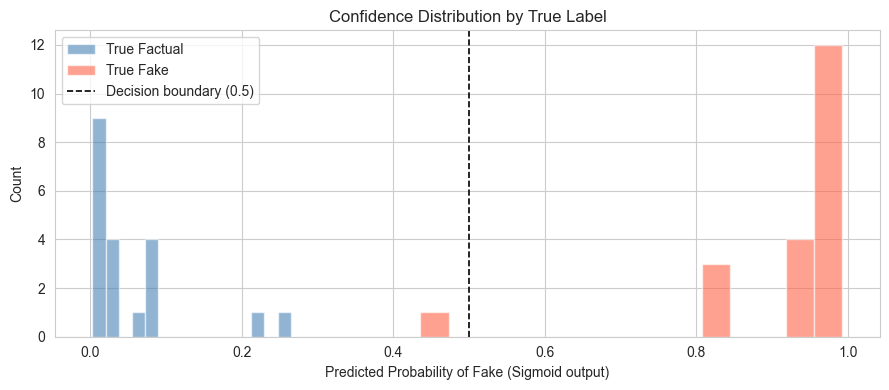

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))

factual_probs = y_prob[y_test.values == 0]
fake_probs    = y_prob[y_test.values == 1]

ax.hist(factual_probs, bins=15, alpha=0.6, color='steelblue', label='True Factual')
ax.hist(fake_probs,    bins=15, alpha=0.6, color='tomato',    label='True Fake')
ax.axvline(0.5, color='black', linestyle='--', linewidth=1.2, label='Decision boundary (0.5)')
ax.set_xlabel('Predicted Probability of Fake (Sigmoid output)')
ax.set_ylabel('Count')
ax.set_title('Confidence Distribution by True Label')
ax.legend()
plt.tight_layout()
plt.show()

## 10. Phase Summary

Key decisions and lecture-backed reasoning:

In [12]:
from sklearn.metrics import f1_score

f1_fake    = f1_score(y_test, y_pred, pos_label=1)
f1_factual = f1_score(y_test, y_pred, pos_label=0)

summary = pd.DataFrame([{
    'Model': 'Feedforward Neural Network (Keras)',
    'Architecture': '5000 → 256 → 128 → 64 → 1',
    'Optimizer': 'Adam',
    'Loss': 'Binary Cross-Entropy',
    'Epochs Run': len(history.history['loss']),
    'Test Accuracy': f'{test_acc:.2%}',
    'F1 (Fake)': f'{f1_fake:.4f}',
    'F1 (Factual)': f'{f1_factual:.4f}',
}])

summary.T

,0
Model,Feedforward Neural Network (Keras)
Architecture,5000 → 256 → 128 → 64 → 1
Optimizer,Adam
Loss,Binary Cross-Entropy
Epochs Run,23
Test Accuracy,97.50%
F1 (Fake),0.9744
F1 (Factual),0.9756


## 11. Save Model Artifacts

Export both the **TF-IDF vectorizer** and the **trained Keras model** so the
FastAPI backend can load them without re-training.

-  — saved with joblib (sklearn object, unchanged)
-  — saved in the native Keras format (recommended over )

In [ ]:
import joblib
import os

BACKEND_DIR = os.path.join(os.path.dirname(os.path.abspath("__file__")), "backend")

# Save TF-IDF vectorizer
vectorizer_path = os.path.join(BACKEND_DIR, "vectorizer.pkl")
joblib.dump(tfidf, vectorizer_path)
print(f"Vectorizer saved → {vectorizer_path}")

# Save Keras model in native .keras format
model_path = os.path.join(BACKEND_DIR, "nn_model.keras")
model.save(model_path)
print(f"Keras model saved  → {model_path}")
print(f"Model input shape  : {model.input_shape}")
print(f"Vocab size         : {len(tfidf.vocabulary_)}")